# RFM Analysis


## Import et chargement

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 14,
                     "axes.titleweight": "bold", "axes.labelsize": 11})

# Load the cleaned dataset produced in notebook 01
df = pd.read_csv("...data/marketing_campaign_clean.csv")
print(df.shape)

(2240, 30)


### Calcul de R, F et M par client

In [13]:
spend_cols = ["MntWines", "MntFruits", "MntMeatProducts",
              "MntFishProducts", "MntSweetProducts", "MntGoldProds"]

channel_cols = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"] 

#NumDealsPurchases isn't considered because it is in  other type of purchase, eg: I can purchase a product through website with discount"""


rfm = pd.DataFrame({
    "Recency":   df["Recency"],                    # days since last purchase (lower = better)
    "Frequency": df[channel_cols].sum(axis=1),     # total number of purchases (all channels)
    "Monetary":  df[spend_cols].sum(axis=1),       # total spent over 2 years
    "Response":  df["Response"],                   # kept to link segments to campaign results
    "Income":    df["Income"],
})
rfm.index.name = "CustomerID"

# Recency is required to score a customer: drop rows where it is missing
n_before = len(rfm)
rfm = rfm.dropna(subset=["Recency"])
print(f"Rows dropped (missing Recency): {n_before - len(rfm)}")

# Quick sanity checks
print("Customers with Frequency = 0:", (rfm["Frequency"] == 0).sum())
print("Customers with Frequency = 0 but Monetary > 0:",
      ((rfm["Frequency"] == 0) & (rfm["Monetary"] > 0)).sum())
rfm.describe().T

Rows dropped (missing Recency): 0
Customers with Frequency = 0: 6
Customers with Frequency = 0 but Monetary > 0: 6


,count,mean,std,min,25%,50%,75%,max
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.0,99.0
Frequency,2240.0,12.537054,7.205741,0.0,6.00,12.0,18.0,32.0
Monetary,2240.0,605.798214,602.249288,5.0,68.75,396.0,1045.5,2525.0
Response,2240.0,0.149107,0.356274,0.0,0.00,0.0,0.0,1.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.0,666666.0


### Scores de 1 to 5 (quintiles)

In [16]:
def quintile_score(series, ascending=True):
    """Split a series into 5 equal-sized groups and return scores 1-5.
    rank(method='first') breaks ties so qcut never fails on repeated values."""
    ranks = series.rank(method="first", ascending=ascending)
    return pd.qcut(ranks, 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Recency: a LOW number of days is good -> reverse the ranking so that 5 = most recent
rfm["R_score"] = quintile_score(rfm["Recency"], ascending=False)
rfm["F_score"] = quintile_score(rfm["Frequency"], ascending=True)
rfm["M_score"] = quintile_score(rfm["Monetary"], ascending=True)

# Combined value score (average of F and M) and a readable RFM code such as "545"
rfm["FM_score"] = (rfm["F_score"] + rfm["M_score"]) / 2
rfm["RFM_code"] = (rfm["R_score"].astype(str) + rfm["F_score"].astype(str)
                   + rfm["M_score"].astype(str))

rfm[["Recency", "Frequency", "Monetary", "R_score", "F_score", "M_score", "RFM_code"]].head(10)

,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_code
CustomerID,,,,,,,
0,58.0,22.0,1617.0,3,5,5,355
1,38.0,4.0,27.0,4,1,1,411
2,26.0,20.0,776.0,4,4,4,444
3,26.0,6.0,53.0,4,2,1,421
4,94.0,14.0,422.0,1,3,3,133
5,16.0,20.0,716.0,5,4,4,544
6,34.0,17.0,590.0,4,4,3,443
7,32.0,8.0,169.0,4,2,2,422
8,19.0,5.0,46.0,4,1,1,411


### Règles de segmentation

In [19]:
# Business rules, evaluated in order (first match wins)
conditions = [
    (rfm["R_score"] >= 4) & (rfm["FM_score"] >= 4),   # recent + high value
    (rfm["R_score"] >= 3) & (rfm["FM_score"] >= 3),   # fairly recent + good value
    (rfm["R_score"] >= 4) & (rfm["FM_score"] < 3),    # recent + low value so far
    (rfm["R_score"] == 3) & (rfm["FM_score"] < 3),    # average recency + low value
    (rfm["R_score"] <= 2) & (rfm["FM_score"] >= 3),   # inactive but valuable
    (rfm["R_score"] <= 2) & (rfm["FM_score"] < 3),    # inactive + low value
]
labels = ["Champions", "Loyal Customers", "Promising", "Need Attention",
          "At Risk", "Hibernating"]

rfm["Segment"] = np.select(conditions, labels, default="Other")

segment_order = labels
print(rfm["Segment"].value_counts().reindex(segment_order))
print("Unassigned:", (rfm["Segment"] == "Other").sum())

Segment
Champions          327
Loyal Customers    463
Promising          367
Need Attention     187
At Risk            546
Hibernating        350
Name: count, dtype: int64
Unassigned: 0


### Profil de chaque segment

In [22]:
profile = (rfm.groupby("Segment")
              .agg(customers=("Segment", "size"),
                   avg_recency=("Recency", "mean"),
                   avg_frequency=("Frequency", "mean"),
                   avg_monetary=("Monetary", "mean"),
                   total_monetary=("Monetary", "sum"),
                   response_rate_pct=("Response", lambda s: 100 * s.mean()),
                   avg_income=("Income", "mean")))

profile["pct_customers"] = 100 * profile["customers"] / profile["customers"].sum()
profile["pct_revenue"] = 100 * profile["total_monetary"] / profile["total_monetary"].sum()

profile = profile.reindex([s for s in segment_order if s in profile.index]).round(1)
profile

,customers,avg_recency,avg_frequency,avg_monetary,total_monetary,response_rate_pct,avg_income,pct_customers,pct_revenue
Segment,,,,,,,,,
Champions,327,18.4,20.3,1251.6,409274.0,33.3,72085.9,14.6,30.2
Loyal Customers,463,36.7,15.7,754.1,349170.0,16.6,59618.4,20.7,25.7
Promising,367,18.9,5.1,69.6,25554.0,15.8,35037.0,16.4,1.9
Need Attention,187,48.7,5.2,66.8,12483.0,6.4,32391.7,8.3,0.9
At Risk,546,78.8,17.4,981.5,535924.0,12.3,64191.2,24.4,39.5
Hibernating,350,79.8,5.2,70.2,24583.0,3.1,33803.2,15.6,1.8


### Graphiques de synthèse

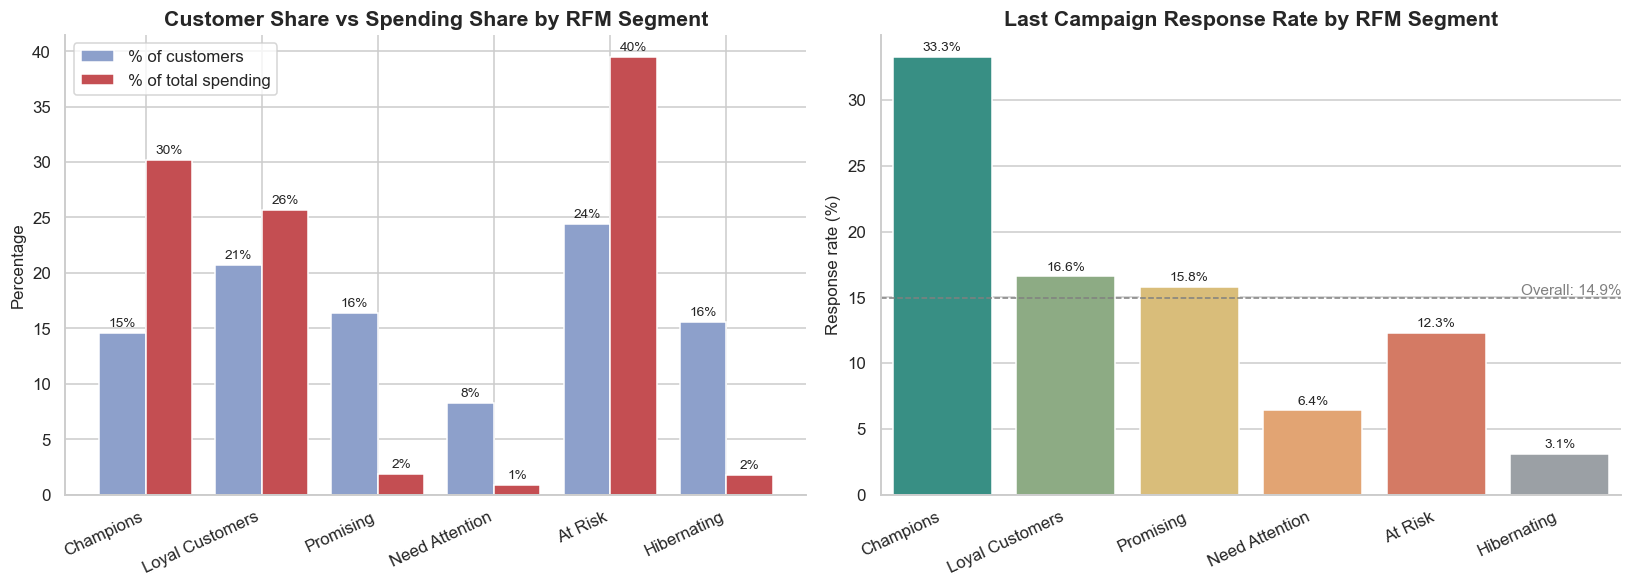

In [25]:
palette = {"Champions": "#2a9d8f", "Loyal Customers": "#8ab17d", "Promising": "#e9c46a",
           "Need Attention": "#f4a261", "At Risk": "#e76f51", "Hibernating": "#9aa0a6"}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
x = np.arange(len(profile))
w = 0.4

# Left: share of customers vs share of spending per segment
axes[0].bar(x - w / 2, profile["pct_customers"], w, label="% of customers", color="#8da0cb")
axes[0].bar(x + w / 2, profile["pct_revenue"], w, label="% of total spending", color="#c44e52")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.0f%%", padding=2, fontsize=9)
axes[0].set_xticks(x)
axes[0].set_xticklabels(profile.index, rotation=25, ha="right")
axes[0].set_title("Customer Share vs Spending Share by RFM Segment")
axes[0].set_ylabel("Percentage")
axes[0].legend()

# Right: response rate to the last campaign per segment
sns.barplot(x=profile.index, y=profile["response_rate_pct"], hue=profile.index,
            palette=palette, legend=False, ax=axes[1])
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.1f%%", padding=2, fontsize=9)
overall = 100 * rfm["Response"].mean()
axes[1].axhline(overall, color="grey", linestyle="--", linewidth=1)
axes[1].text(len(profile) - 0.5, overall + 0.3, f"Overall: {overall:.1f}%",
             ha="right", color="grey", fontsize=10)
axes[1].set_xticks(x)
axes[1].set_xticklabels(profile.index, rotation=25, ha="right")
axes[1].set_title("Last Campaign Response Rate by RFM Segment")
axes[1].set_xlabel("")
axes[1].set_ylabel("Response rate (%)")

sns.despine()
plt.tight_layout()
plt.show()

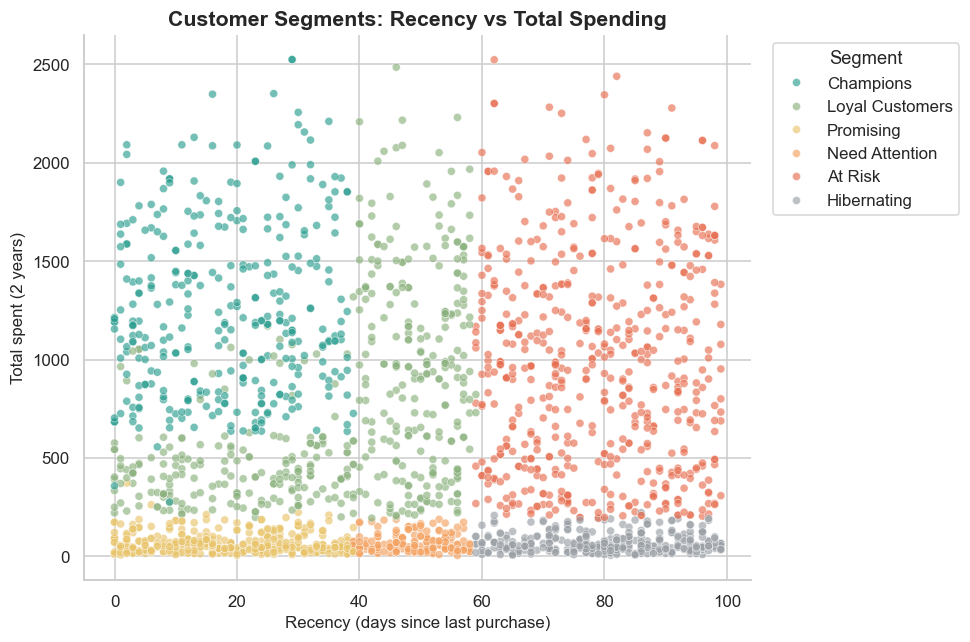

In [30]:
# Scatter plot: Recency vs Monetary, coloured by segment
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=rfm, x="Recency", y="Monetary", hue="Segment",
                hue_order=[s for s in segment_order if s in profile.index],
                palette=palette, alpha=0.65, s=28, ax=ax)
ax.set_title("Customer Segments: Recency vs Total Spending")
ax.set_xlabel("Recency (days since last purchase)")
ax.set_ylabel("Total spent (2 years)")
ax.legend(title="Segment", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

### Chiffres clés et paragraphe de synthèse automatique

In [28]:
def seg(name, col):
    """Safe lookup in the profile table (NaN if the segment does not exist)."""
    return profile.loc[name, col] if name in profile.index else float("nan")

# Pareto effect: share of spending coming from the top 20% of customers
top20 = rfm.sort_values("Monetary", ascending=False).head(int(0.2 * len(rfm)))
pareto = 100 * top20["Monetary"].sum() / rfm["Monetary"].sum()

summary = f"""
Top 20% des clients  -> {pareto:.1f}% des dépenses totales
Champions            -> {seg('Champions','pct_customers'):.1f}% des clients, {seg('Champions','pct_revenue'):.1f}% des dépenses, réponse {seg('Champions','response_rate_pct'):.1f}%
At Risk              -> {seg('At Risk','pct_customers'):.1f}% des clients, {seg('At Risk','pct_revenue'):.1f}% des dépenses, réponse {seg('At Risk','response_rate_pct'):.1f}%
Hibernating          -> {seg('Hibernating','pct_customers'):.1f}% des clients, {seg('Hibernating','pct_revenue'):.1f}% des dépenses, réponse {seg('Hibernating','response_rate_pct'):.1f}%
Réponse globale      -> {overall:.1f}%
"""
print(summary)


Top 20% des clients  -> 52.3% des dépenses totales
Champions            -> 14.6% des clients, 30.2% des dépenses, réponse 33.3%
At Risk              -> 24.4% des clients, 39.5% des dépenses, réponse 12.3%
Hibernating          -> 15.6% des clients, 1.8% des dépenses, réponse 3.1%
Réponse globale      -> 14.9%



## Saving

In [ ]:
# Save the RFM table for later notebooks / dashboards
rfm.reset_index().to_csv("data/customers_rfm.csv", index=False)
print("Saved: data/customers_rfm.csv")